## **```CHIRAG VYAS -```**
## **```AIML PROJECT 03 - AI BASED Customer Behaviour Prediction Platform```**
## **```FEATURE ENGINEERING```**

- **Name:** VANTARA RETAIL SOLUTIONS
- **AIML:** Machine Learning & Deep Learning System for Churn, Lifetime Value, and Purchase Behavior Prediction
- **Analytical System:** Customer Churn, Lifetime Value, Purchase Behavior, Segmentation & Recommendation
- **File Name:** `05_explainibility.ipynb`

## **INDEX**


|`Sr No.`|`Section ID`| `Description`|
|--|---|-----|
||**SHAP- (SHapley Additive exPlanations)**|
|**1**|**Step 1**|[Loading model artifacts:](#Step-1-Loading-model-artifacts:)|
|**2**|**Step 2**|[Shap Analysis Function:](#Step-2-Shap-Analysis-Function:)|
|**3**|**Step 3**|[feature importance table for model and actual:](#Step-3-feature-importance-table-for-model-and-actual:)|
|**4**|**Step 4**|[Create The Genuine SHAP Summary Plot)](#Step-4-Create-The-Genuine-SHAP-Summary-Plot:)|
|**4**|**Step 5**|[Individual Customer Churn Prediction explainibility:](#Step-5-Individual-Customer-Churn-Prediction-explainibility:)|
|**5**|**Step 6**|[Global explainibility Summary:](#Step-6-Global-explainibility-Summary:)|
||**LIME - (Local Interpretable Model-Agnostic Explaination)**|
|**1**|**Step 1**|[Load train-test and validation dataset for explainibility:](#Step-1-Load-train---test-and-validation-dataset-for-explainibility:)|
|**2**|**Step 2**|[Explain customer classification with Lime:](#Step-2-Explain-customer-classification-with-Lime:)|
|**3**|**Step 3**|[Compare Lime With shap Explainibility:](#Step-3-Compare-Lime-With-shap-Explainibility:)|
|**4**|**Step 4**|[Partial Dependence Plot (PDP):](#Step-4-Partial-Dependence-Plot-(PDP):)|
|**5**|**Step 5**|[Plain language explanation template:](#Step-5-Plain-language-explanation-template:)|
|**6**|**Step 6**|[Checklist and Reporting:](#Step-6-Checklist-and-Reporting:)|












In [1]:
############################### DATA WRANGLING / PREPROCESSING LIBRARY  #######################################
#-----------Importing Library for data mathematics -----------
import numpy as np
import pandas as pd
import math
import ast

#------------Importing Library for visulization-----------------
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

#-----------Import warning module to handle future warnning -------
import warnings
warnings.filterwarnings('ignore',category=FutureWarning)

#------------Import precosssing model--------------
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import LabelEncoder

########################################## MACHINE LEARNING MODEL ##############################################

#----------Import Machine Learning Libraries------------
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import RandomizedSearchCV

#----------Importing LinearModel------------------------
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.linear_model import ElasticNet
from sklearn.svm import SVR
from sklearn.naive_bayes import GaussianNB


#----------Importing Ensembled Model - regression---------------------
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.ensemble import GradientBoostingRegressor
from xgboost import XGBRegressor

#----------Importing Ensembled Model - classification---------------------
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import  GradientBoostingClassifier
from xgboost import XGBClassifier

#----------Importing Library for evaluation of models----
from sklearn.metrics import root_mean_squared_error,mean_absolute_error,r2_score,mean_squared_error
from sklearn.metrics import confusion_matrix, f1_score, recall_score, accuracy_score, precision_score, balanced_accuracy_score
from sklearn.metrics import roc_curve,roc_auc_score


####################################### DEEP LEARNING MODEL ######################################################

#----------Importing Deeplearning Model Libraries -----------
from tensorflow.keras.layers import Input, Dense, Conv2D, LSTM, Dropout, Flatten
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.optimizers import Adam,SGD
from tensorflow.keras.callbacks import EarlyStopping

########################################### IMPORTING FOR DASHBOARD ##############################################
import streamlit as st
import sys
from pathlib import Path

##################################################################################################################

#import yfinance as yf
#from pandas_datareader import data as web
from datetime import datetime, timedelta
import re
#import pandas_market_calendars as mcal

In [2]:
project_root = Path.cwd().parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

**[GO TO INDEX](#INDEX)**

## **``Step 1 Loading model artifacts:``**

In [3]:
from src.data.ingest import load_config, get_project_root
config=load_config()

In [4]:
import importlib
import src.models.model_persistance as model_persistance
importlib.reload(model_persistance)
from src.models.model_persistance import load_model_artifacts

In [5]:
xgboost_bundle = load_model_artifacts(
    config=config,
    get_project_root=get_project_root,
    model_key="xgboost",
    model_type="classification",
    X_validation=None,
)

print(xgboost_bundle["validation_report"])
print(xgboost_bundle["best_params"])
print(xgboost_bundle["feature_names"])

{'artifact_exists': True, 'artifact_loaded': True, 'estimator_class': 'XGBClassifier', 'feature_count': 27, 'feature_names_available': True, 'preprocessing_available': False, 'prediction_smoke_test_passed': None}
{'subsample': 0.8, 'n_estimators': 200, 'max_depth': 3, 'learning_rate': 0.01, 'colsample_bytree': 1.0}
[np.str_('Recency'), np.str_('Frequency'), np.str_('Total_Monetary_Value'), np.str_('Average_Order_Spend'), np.str_('Customer_Lifetime_Days'), np.str_('Average_Basket_Size'), np.str_('Purchase_Frequency_Trend'), np.str_('Interpurchase_Variance'), np.str_('Seasonal_Purchase_Concentration'), np.str_('Home_Fragrance_Affinity'), np.str_('Lighting_Candles_Affinity'), np.str_('Stationery_Paper_Affinity'), np.str_('Jewelry_Fashion_Accessories_Affinity'), np.str_('Bags_Travel_Accessories_Affinity'), np.str_('Kitchen_Dining_Affinity'), np.str_('Storage_Organization_Affinity'), np.str_('Garden_Outdoor_Affinity'), np.str_('Bath_Personal_Care_Affinity'), np.str_('Toys_Games_Affinity'), 

**[GO TO INDEX](#INDEX)**

## **``Step 2 Shap Analysis Function:``**

In [6]:
import importlib
import src.explainability.shap_explainer as shap_explainer
importlib.reload(shap_explainer)
from src.explainability.shap_explainer import run_shap_analysis

In [7]:
import pandas as pd
from pathlib import Path

# Set the directory containing the saved validation files
project_root = get_project_root()

explainability_dir = (
    Path(project_root)
    / "model_artifacts"
    / "explainability"
)

# Load validation features and actual churn labels
X_validation = pd.read_csv(explainability_dir / "xgboost_validation_features.csv")

y_validation = pd.read_csv(explainability_dir / "xgboost_validation_labels.csv")["Churn"]

print("Validation features shape:", X_validation.shape)
print("Validation labels shape:", y_validation.shape)
print("Features loaded successfully:", X_validation.shape[1] == 27)

Validation features shape: (792, 27)
Validation labels shape: (792,)
Features loaded successfully: True


In [8]:
X_validation.columns

Index(['Recency', 'Frequency', 'Total_Monetary_Value', 'Average_Order_Spend',
       'Customer_Lifetime_Days', 'Average_Basket_Size',
       'Purchase_Frequency_Trend', 'Interpurchase_Variance',
       'Seasonal_Purchase_Concentration', 'Home_Fragrance_Affinity',
       'Lighting_Candles_Affinity', 'Stationery_Paper_Affinity',
       'Jewelry_Fashion_Accessories_Affinity',
       'Bags_Travel_Accessories_Affinity', 'Kitchen_Dining_Affinity',
       'Storage_Organization_Affinity', 'Garden_Outdoor_Affinity',
       'Bath_Personal_Care_Affinity', 'Toys_Games_Affinity',
       'Party_Celebration_Affinity', 'Gifts_Seasonal_Affinity',
       'Food_Consumables_Affinity', 'Home_Decor_Affinity',
       'Other___Unclassified_Affinity', 'Return_Rate',
       'Discount_Markdown_Sensitivity', 'Engagement_Score'],
      dtype='str')

In [12]:
import shap

# Create SHAP explainer for the trained XGBoost model
explainer = shap.TreeExplainer(xgboost_bundle["model"])

print("SHAP explainer created successfully.")

shap_analysis = run_shap_analysis(
    model=xgboost_bundle["model"],
    explainer=explainer,
    X_validation=X_validation,
    feature_names=xgboost_bundle["feature_names"],
    y_validation=y_validation,
)

customer_details = shap_analysis["customer_explanation"]

SHAP explainer created successfully.
SHAP ANALYSIS VALIDATION
Validation data shape : (792, 27)
Expected feature count: 27
Feature validation    : PASSED

SHAP calculation      : COMPLETED
SHAP values shape     : (792, 27)

PREDICTION SUMMARY
-----------------------------------------------------------------
Total customers       : 792
Predicted churn       : 511
Predicted no churn    : 281

SELECTED CUSTOMER: 0
Predicted class : 1
Prediction      : Churn

CLASS PROBABILITIES
-----------------------------------
No Churn    : 14.69%
Churn       : 85.31%

Actual outcome : Churn
Prediction correct: True

CUSTOMER FEATURE DETAILS
-----------------------------------------------------------------
                             Feature    Value
                             Recency 527.9900
                           Frequency   1.0000
                Total_Monetary_Value 253.8800
                 Average_Order_Spend 253.8800
              Customer_Lifetime_Days   0.0000
                 Average_

In [13]:
print(customer_details["class_probabilities"])

{'0': 0.14690357446670532, '1': 0.8530964255332947}


**[GO TO INDEX](#INDEX)**

## **``Step 3 feature importance table for model and actual:``**

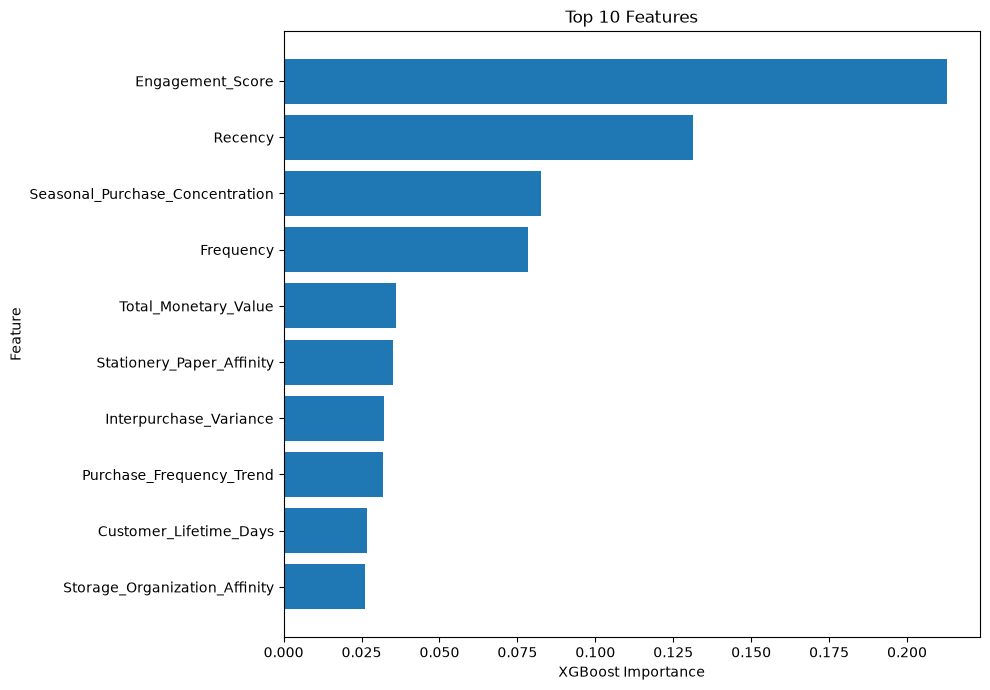


Feature importance table:
                        Feature  XGBoost_Importance
               Engagement_Score            0.212766
                        Recency            0.131450
Seasonal_Purchase_Concentration            0.082574
                      Frequency            0.078343
           Total_Monetary_Value            0.036200
      Stationery_Paper_Affinity            0.034954
         Interpurchase_Variance            0.032201
       Purchase_Frequency_Trend            0.032036
         Customer_Lifetime_Days            0.026793
  Storage_Organization_Affinity            0.026004

Full table saved to: E:\10. Internmo Projects\AIML_internmo_Project3_Vantara\2.AIML_Project3_Vantara_retail_solution\customer-behaviour-prediction\model_artifacts\explainability\plots\xgboost_feature_importance.csv
Plot saved to: E:\10. Internmo Projects\AIML_internmo_Project3_Vantara\2.AIML_Project3_Vantara_retail_solution\customer-behaviour-prediction\model_artifacts\explainability\plots\xgboost

In [14]:
import importlib
import src.explainability.shap_explainer as shap_explainer
importlib.reload(shap_explainer)
from src.explainability.shap_explainer import plot_feature_importance

project_root = get_project_root()
plot_dir = (Path(project_root)/ "model_artifacts"/ "explainability"/ "plots")

model = xgboost_bundle["model"]
feature_names = xgboost_bundle["feature_names"]

importance_result = plot_feature_importance(
    model=model,
    feature_names=feature_names,
    output_dir=plot_dir,
    top_n=10,
    show=True,
)

feature_importance = importance_result["importance_table"]


SHAP values extracted successfully.
SHAP values shape: (792, 27)


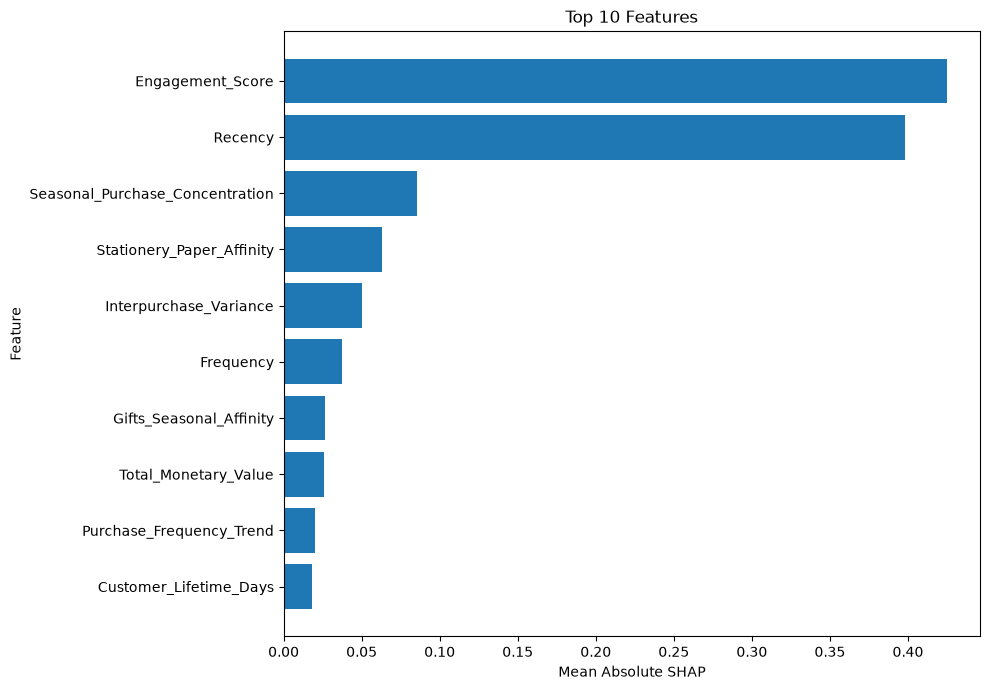


Feature importance table:
                        Feature  Mean_Absolute_SHAP
               Engagement_Score            0.424906
                        Recency            0.397896
Seasonal_Purchase_Concentration            0.085425
      Stationery_Paper_Affinity            0.063278
         Interpurchase_Variance            0.050521
                      Frequency            0.037482
        Gifts_Seasonal_Affinity            0.026316
           Total_Monetary_Value            0.025667
       Purchase_Frequency_Trend            0.020431
         Customer_Lifetime_Days            0.017918

Full table saved to: E:\10. Internmo Projects\AIML_internmo_Project3_Vantara\2.AIML_Project3_Vantara_retail_solution\customer-behaviour-prediction\model_artifacts\explainability\plots\shap_feature_importance.csv
Plot saved to: E:\10. Internmo Projects\AIML_internmo_Project3_Vantara\2.AIML_Project3_Vantara_retail_solution\customer-behaviour-prediction\model_artifacts\explainability\plots\shap_featu

In [15]:
shap_values = shap_analysis["shap_values"]

print("SHAP values extracted successfully.")
print("SHAP values shape:", shap_values.values.shape)
shap_importance_result = plot_feature_importance(
    model=model,
    feature_names=feature_names,
    output_dir=plot_dir,
    top_n=10,
    shap_values=shap_values,
    show=True,
)

shap_importance_table = (
    shap_importance_result["importance_table"]
)


**[GO TO INDEX](#INDEX)**

## **``Step 4 Create The Genuine SHAP Summary Plot:``**

In [16]:
import importlib
import src.explainability.shap_explainer as shap_explainer
importlib.reload(shap_explainer)

from src.explainability.shap_explainer import explain_global_summary
from src.explainability.shap_explainer import explain_customer_waterfall

In [17]:
# Retrieve the validated features and SHAP values
X_explain = shap_analysis["X_explain"]
shap_values = shap_analysis["shap_values"]

# Retrieve the selected customer
customer_idx = shap_analysis["customer_idx"]

print("X_explain shape:", X_explain.shape)
print("SHAP values shape:", shap_values.values.shape)
print("Selected customer index:", customer_idx)

X_explain shape: (792, 27)
SHAP values shape: (792, 27)
Selected customer index: 0


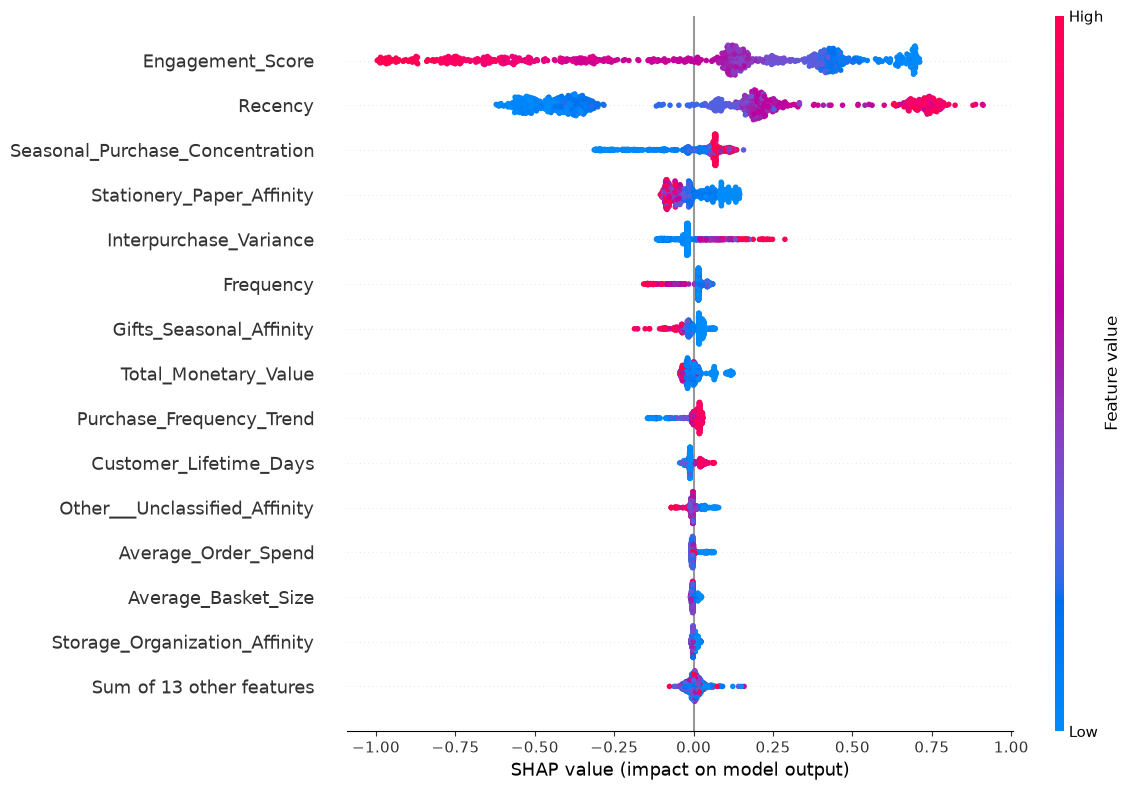

SHAP summary plot saved to: E:\10. Internmo Projects\AIML_internmo_Project3_Vantara\2.AIML_Project3_Vantara_retail_solution\customer-behaviour-prediction\model_artifacts\explainability\plots\shap_summary_dot.png


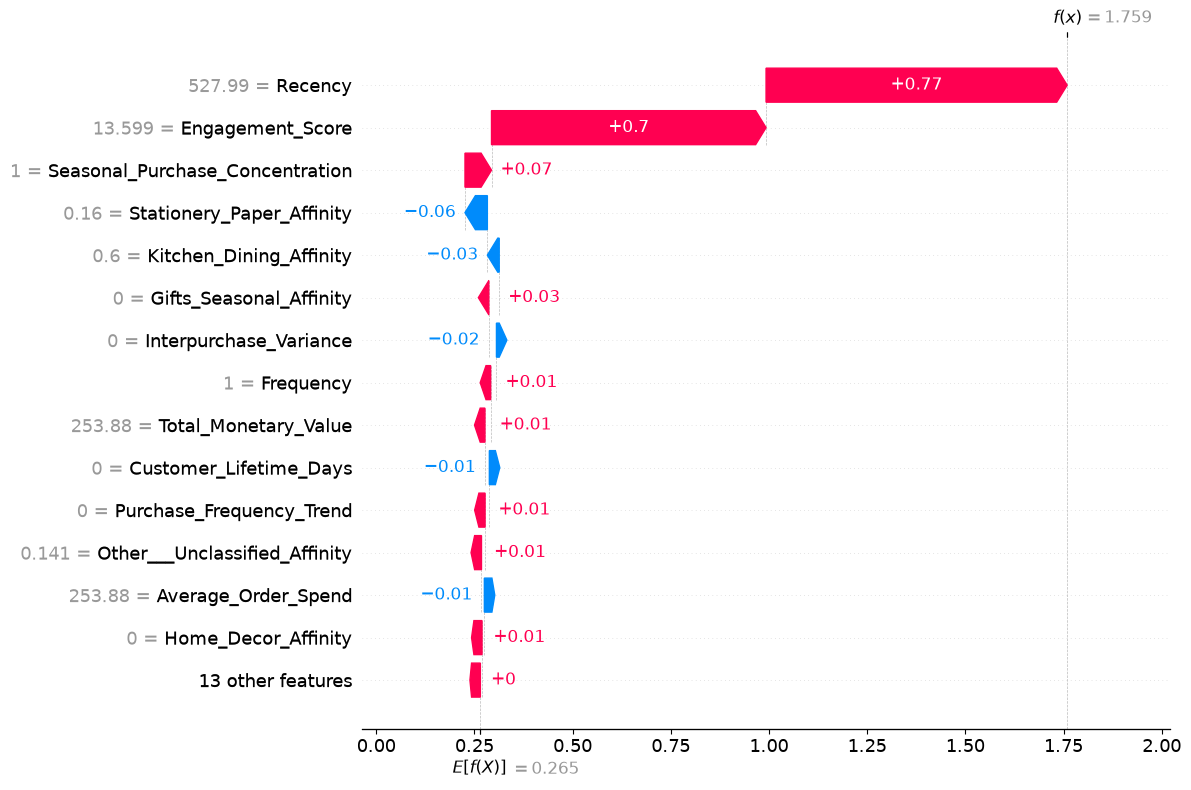

SHAP waterfall saved to: E:\10. Internmo Projects\AIML_internmo_Project3_Vantara\2.AIML_Project3_Vantara_retail_solution\customer-behaviour-prediction\model_artifacts\explainability\plots\customer_0_shap_waterfall.png
Predicted class: 1
Class probabilities: {'0': 0.14690357446670532, '1': 0.8530964255332947}


In [18]:
project_root = get_project_root()
plot_dir = (project_root/ "model_artifacts"/ "explainability"/ "plots")

# Plot 1: Global SHAP summary (beeswarm)
summary_result = explain_global_summary(
    explainer=explainer,
    X=X_explain,
    output_dir=plot_dir,
    max_display=15,
    plot_type="dot",
    show=True,
)

# Plot 2: Individual customer waterfall
customer_result = explain_customer_waterfall(
    model=xgboost_bundle["model"],
    explainer=explainer,
    X=X_explain,
    customer_idx=customer_idx,
    output_dir=plot_dir,
    max_display=15,
    show=True,
)


## **``Step 5 Individual Customer Churn Prediction explainibility:``**

In [19]:
import importlib
import src.explainability.shap_explainer as shap_explainer
importlib.reload(shap_explainer)
from src.explainability.shap_explainer import explain_customer_for_dashboard
from src.explainability.shap_explainer import explain_global_for_dashboard

Prediction: Churn
Probabilities: {'0': 0.4831627607345581, '1': 0.5168372392654419}


,Feature,Value,SHAP_Value,Absolute_SHAP
0,Recency,50.970000,-0.447272,0.447272
1,Engagement_Score,46.714637,0.128212,0.128212
2,Seasonal_Purchase_Concentration,0.500000,0.126686,0.126686
3,Stationery_Paper_Affinity,0.125972,-0.079427,0.079427
4,Frequency,2.000000,0.049227,0.049227
5,Customer_Lifetime_Days,595.900000,0.048136,0.048136
6,Interpurchase_Variance,0.000000,-0.034215,0.034215
7,Gifts_Seasonal_Affinity,0.115131,-0.027967,0.027967
8,Purchase_Frequency_Trend,-0.002259,0.026625,0.026625
9,Other___Unclassified_Affinity,0.349717,-0.015284,0.015284


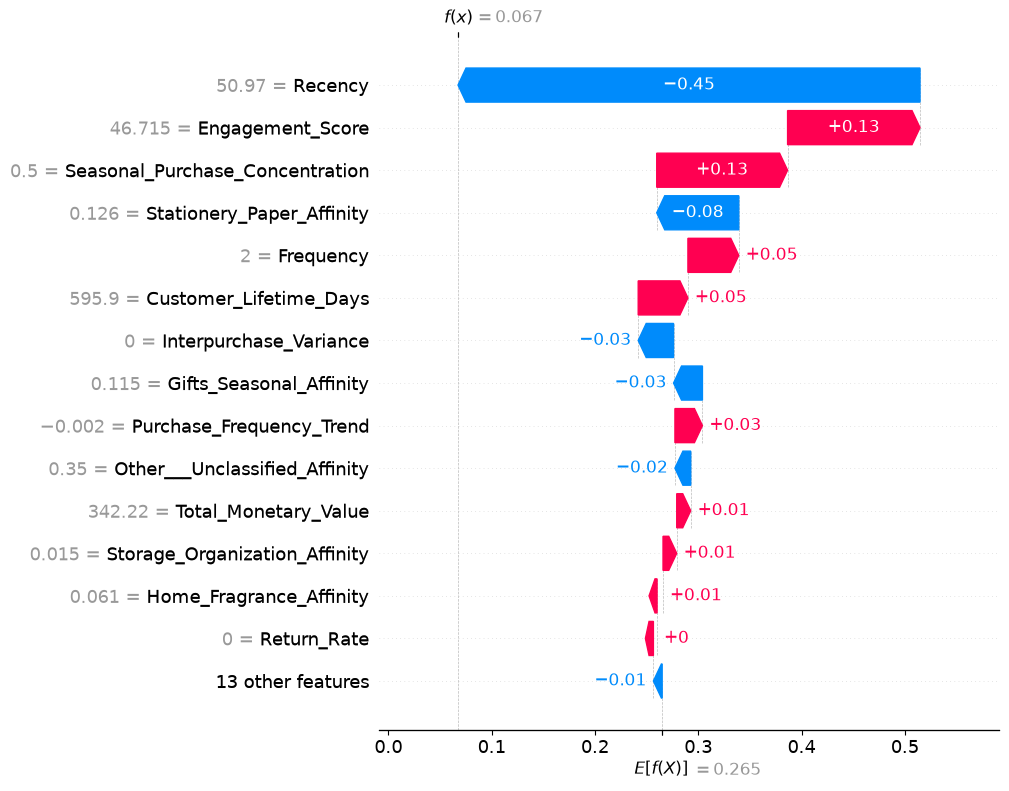

In [21]:
customer_idx = 3

customer_result = explain_customer_for_dashboard(
    model=xgboost_bundle["model"],
    explainer=explainer,
    customer_features=X_validation.iloc[[customer_idx]],
)

print("Prediction:", customer_result["prediction_label"])
print("Probabilities:", customer_result["probabilities"])

display(customer_result["contributions"])

plt.show()

**[GO TO INDEX](#INDEX)**

## **``Step 6 Global explainibility Summary:``** 

,Feature,Mean_Absolute_SHAP
0,Engagement_Score,0.424906
1,Recency,0.397896
2,Seasonal_Purchase_Concentration,0.085425
3,Stationery_Paper_Affinity,0.063278
4,Interpurchase_Variance,0.050521
5,Frequency,0.037482
6,Gifts_Seasonal_Affinity,0.026316
7,Total_Monetary_Value,0.025667
8,Purchase_Frequency_Trend,0.020431
9,Customer_Lifetime_Days,0.017918


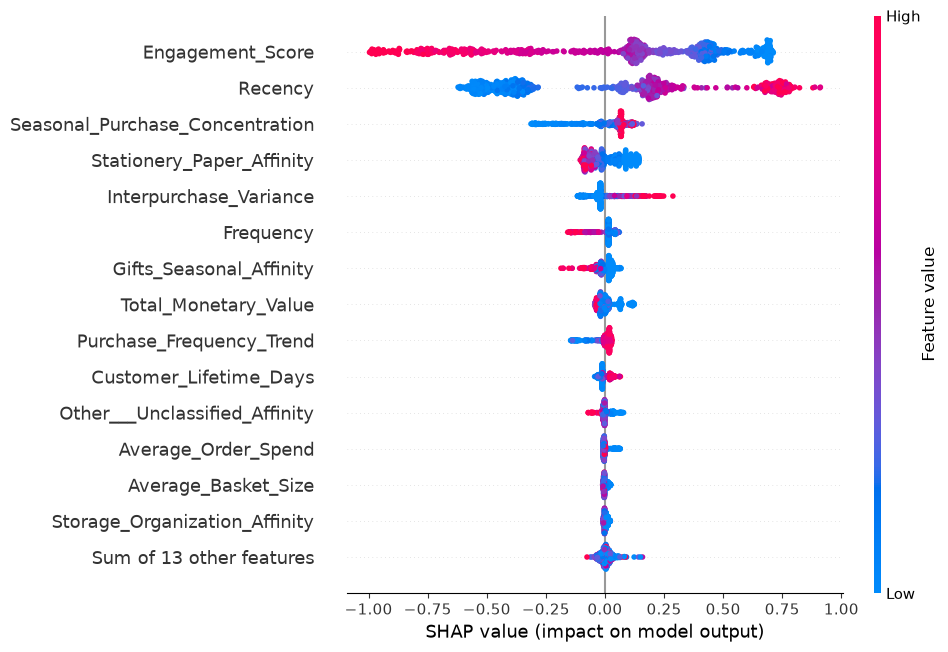

In [23]:
global_result = explain_global_for_dashboard(
    explainer=explainer,
    X=X_validation,
    max_display=15,
)

display(global_result["importance"].head(10))

plt.show()

## **``Local Interpretable Model-Agnostic Explaination``**

## **``Step 1 Load train-test and validation dataset for explainibility:``**

In [29]:

import pandas as pd
from pathlib import Path

project_root = get_project_root()

explainability_dir = (Path(project_root)/ "model_artifacts"/ "explainability")

# Load training data
X_train = pd.read_csv(explainability_dir / "xgboost_train_features.csv")
y_train = pd.read_csv(explainability_dir / "xgboost_train_labels.csv")["Churn"]

# Load validation data
X_validation = pd.read_csv(explainability_dir / "xgboost_validation_features.csv")
y_validation = pd.read_csv(explainability_dir / "xgboost_validation_labels.csv")["Churn"]

# Load test data
X_test = pd.read_csv(explainability_dir / "xgboost_test_features.csv")
y_test = pd.read_csv(explainability_dir / "xgboost_test_labels.csv")["Churn"]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_validation.shape, y_validation.shape)
print("Test:", X_test.shape, y_test.shape)


Training: (3696, 27) (3696,)
Validation: (792, 27) (792,)
Test: (793, 27) (793,)


In [30]:
# verifying dataset
assert len(X_train) == len(y_train)
assert len(X_validation) == len(y_validation)
assert len(X_test) == len(y_test)

expected_features = xgboost_bundle["feature_names"]

assert list(X_train.columns) == list(expected_features)
assert list(X_validation.columns) == list(expected_features)
assert list(X_test.columns) == list(expected_features)

print("All datasets loaded and validated successfully.")

All datasets loaded and validated successfully.


**[GO TO INDEX](#INDEX)**

## **``Step 2 Explain customer classification with Lime:``**

In [31]:
import importlib
import src.explainability.lime_explainer as lime_explainer
importlib.reload(lime_explainer)
from src.explainability.lime_explainer import explain_customer_with_lime

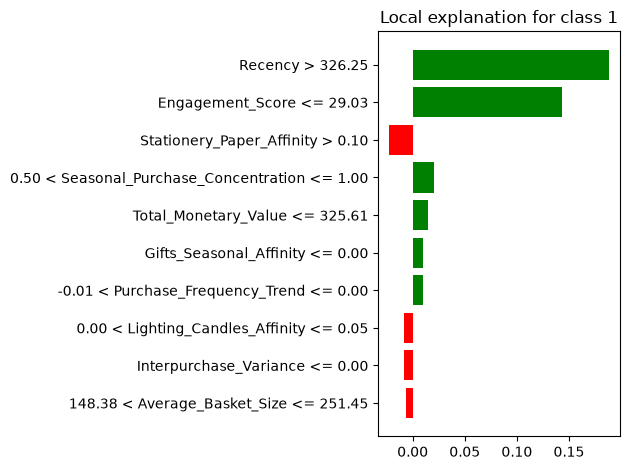

Prediction: Churn
Probabilities: {'0': 0.14690357446670532, '1': 0.8530964255332947}


,Feature_Condition,LIME_Weight,Direction
0,Recency > 326.25,0.188422,Supports churn
1,Engagement_Score <= 29.03,0.143437,Supports churn
2,Stationery_Paper_Affinity > 0.10,-0.022571,Opposes churn
3,0.50 < Seasonal_Purchase_Concentration <= 1.00,0.020093,Supports churn
4,Total_Monetary_Value <= 325.61,0.014608,Supports churn
5,Gifts_Seasonal_Affinity <= 0.00,0.010288,Supports churn
6,-0.01 < Purchase_Frequency_Trend <= 0.00,0.009613,Supports churn
7,0.00 < Lighting_Candles_Affinity <= 0.05,-0.008471,Opposes churn
8,Interpurchase_Variance <= 0.00,-0.008372,Opposes churn
9,148.38 < Average_Basket_Size <= 251.45,-0.006070,Opposes churn


In [32]:

model = xgboost_bundle["model"]

# Reuse the selected customer from your SHAP analysis
customer_idx = shap_analysis["customer_idx"]

lime_result = explain_customer_with_lime(
    model=model,
    X_train=X_train,
    customer_features=X_validation.iloc[[customer_idx]],
    feature_names=xgboost_bundle["feature_names"],
    num_features=10,
    num_samples=5000,
    output_dir=plot_dir,
    show=True,
)

print("Prediction:", lime_result["prediction_label"])
print("Probabilities:", lime_result["class_probabilities"])

display(lime_result["contributions"])

**[GO TO INDEX](#INDEX)**

## **``Step 3 Compare Lime With shap Explainibility:``**

In [33]:
import importlib
import src.explainability.lime_explainer as lime_explainer
importlib.reload(lime_explainer)
from src.explainability.lime_explainer import compare_lime_with_shap

In [34]:
comparison_table = compare_lime_with_shap(
    lime_result=lime_result,
    shap_explanation=shap_analysis["shap_values"],
    customer_idx=customer_idx,
    top_n=10,
)

display(comparison_table)

,Feature,SHAP_Value,LIME_Weight,Absolute_SHAP,Absolute_LIME
0,Recency,0.766640,0.188422,0.766640,0.188422
1,Engagement_Score,0.699064,0.143437,0.699064,0.143437
2,Seasonal_Purchase_Concentration,0.067536,0.000000,0.067536,0.000000
3,Stationery_Paper_Affinity,-0.056957,-0.022571,0.056957,0.022571
4,Kitchen_Dining_Affinity,-0.030157,0.000000,0.030157,0.000000
5,Gifts_Seasonal_Affinity,0.026536,0.010288,0.026536,0.010288
6,Interpurchase_Variance,-0.019534,-0.008372,0.019534,0.008372
7,Frequency,0.014827,0.000000,0.014827,0.000000
8,Total_Monetary_Value,0.014493,0.014608,0.014493,0.014608
9,Customer_Lifetime_Days,-0.011254,0.000000,0.011254,0.000000


**[GO TO INDEX](#INDEX)**

## **``Step 4 Partial Dependence Plot (PDP):``**

In [44]:
import importlib
import src.explainability.pdp_analysis as pdp_analysis
importlib.reload(pdp_analysis)
from src.explainability.pdp_analysis import generate_pdp_analysis

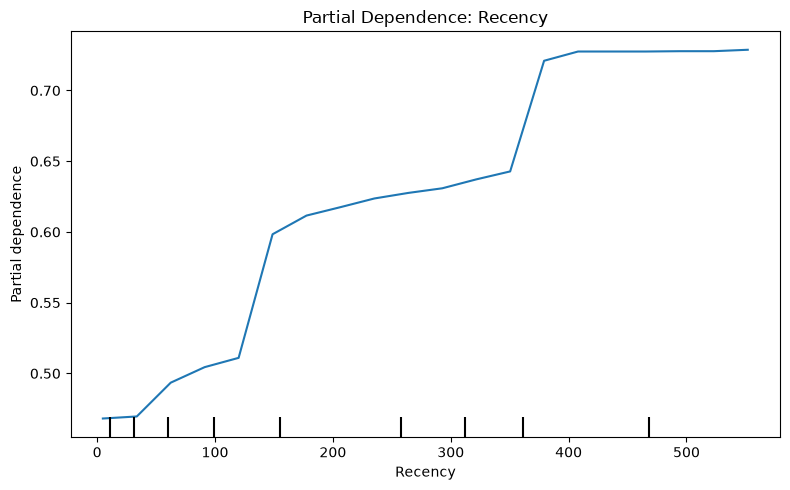

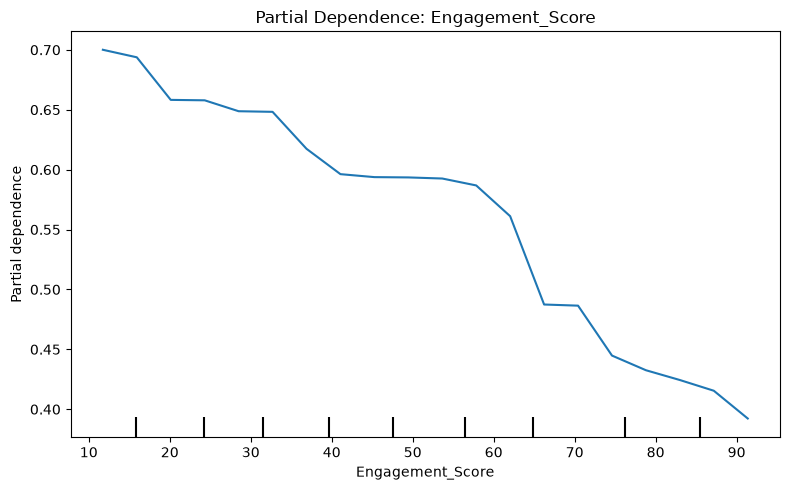

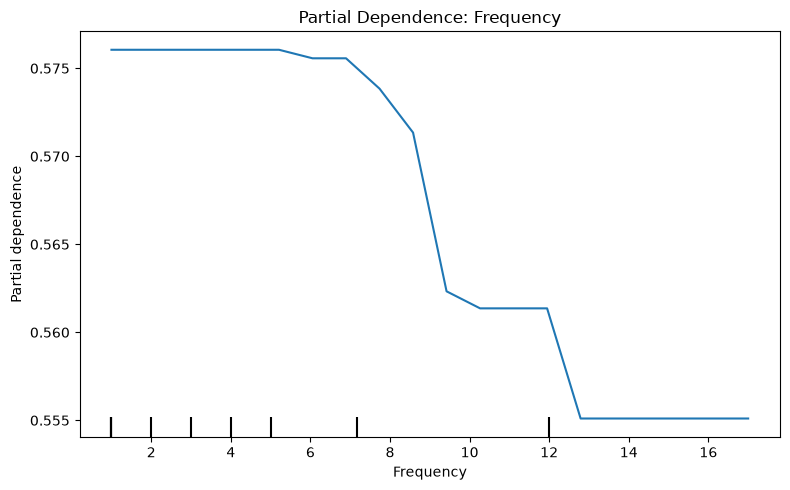

PDP analysis completed successfully.
Target class: 1
Features analysed: ['Recency', 'Engagement_Score', 'Frequency']
Output directory: E:\10. Internmo Projects\AIML_internmo_Project3_Vantara\2.AIML_Project3_Vantara_retail_solution\customer-behaviour-prediction\model_artifacts\explainability\plots


In [45]:
pdp_result = generate_pdp_analysis(
    model=xgboost_bundle["model"],
    X=X_validation,
    features=[
        "Recency",
        "Engagement_Score",
        "Frequency",
    ],
    feature_names=xgboost_bundle["feature_names"],
    output_dir=plot_dir,
    target_class=1,
    grid_resolution=20,
    max_samples=1000,
    show=True,
)

In [46]:
display(pdp_result["pdp_data"]["Recency"])

,Recency,Average_Predicted_Probability
0,4.8504,0.468105
1,33.6467,0.469552
2,62.4430,0.493453
3,91.2393,0.504422
4,120.0356,0.510985
5,148.8319,0.598363
6,177.6282,0.611579
7,206.4245,0.617522
8,235.2208,0.623664
9,264.0171,0.627592


**[GO TO INDEX](#INDEX)**

## **``Step 5 Plain language explanation template:``**

In [48]:
import importlib
import src.explainability.explanation_template as explanation_template
importlib.reload(explanation_template)
from src.explainability.explanation_template import generate_churn_explanation

In [51]:

import pandas as pd

from src.explainability.explanation_template import generate_churn_explanation

customer_idx = shap_analysis["customer_idx"]
shap_explanation = shap_analysis["shap_values"]

# Extract SHAP contributions for this individual customer
customer_shap_contributions = pd.DataFrame({
    "Feature": X_explain.columns,
    "SHAP_Value": shap_explanation.values[customer_idx],
})

# Generate plain-language explanation
customer_details = shap_analysis["customer_explanation"]

plain_language_result = generate_churn_explanation(
    prediction=int(customer_details["predicted_class"]),
    probabilities=customer_details["class_probabilities"],
    contributions=customer_shap_contributions,
    customer_idx=customer_idx,
    top_n=3,
)

print(plain_language_result["explanation_text"])


The model predicts that this customer may churn. The estimated churn probability is 85.3%, classified as High risk using this template's thresholds.

Explanation method: SHAP.
Features supporting the predicted class: Recency, Engagement Score, Seasonal Purchase Concentration.
Features opposing the predicted class: Stationery Paper Affinity, Kitchen Dining Affinity, Interpurchase Variance.

Suggested next step: Consider reviewing this customer's purchase history and engagement before deciding whether a retention campaign is appropriate.


**[GO TO INDEX](#INDEX)**

## **``Step 6 Checklist and Reporting:``**

SHAP
- [x] Global SHAP summary plot generated
- [x] Individual customer waterfall plot generated
- [x] SHAP feature-importance table and CSV saved
- [x] Reusable SHAP functions work

LIME
- [x] Individual LIME explanation generated
- [x] LIME plot and contribution CSV saved
- [x] SHAP–LIME comparison table generated for the same customer

PDP
- [x] Recency PDP generated
- [x] Engagement_Score PDP generated
- [x] Frequency PDP generated
- [x] PDP CSV files saved and no blank plots remain

Plain-language template
- [x] Prediction and churn probability displayed
- [x] Supporting and opposing features identified
- [x] Business recommendation generated

Project quality
- [x] Notebook reruns successfully from a fresh kernel
- [x] Output files exist in the expected directory
- [x] Feature names, customer index and class labels are consistent

## **``Step 7 Checkpoint Review:``**
**Project:** Vantara — Retail Customer Behaviour Prediction

## Objective
Implement explainability components for the trained XGBoost customer churn classification model.

## Work completed

### 1. SHAP Explainability
- Implemented reusable SHAP functions.
- Generated global SHAP summary and feature-importance visualizations.
- Generated individual customer waterfall explanations.
- Retrieved customer-level feature contributions.

### 2. LIME Comparison
- Implemented a reusable LIME explanation function.
- Generated an individual customer LIME explanation and contribution table.
- Compared LIME and SHAP contributions for the same customer.
- Observed agreement on important features, including Recency and Engagement Score.

### 3. Partial Dependence Plots
- Implemented a reusable PDP analysis function.
- Generated PDPs for Recency, Engagement_Score, and Frequency.
- Saved the generated plots and corresponding PDP data.
- Resolved plotting compatibility issues during implementation.

### 4. Plain-language Explanation Template
- Implemented a reusable template to communicate churn predictions.
- Included predicted class, churn probability, supporting and opposing features, and a suggested business action.
- Successfully generated a customer-level explanation.

## Example result
For the selected validation customer, the model predicted churn with an estimated probability of approximately 85.3%. Recency and Engagement Score were among the leading features supporting the prediction.

This is a model prediction, not a guarantee of future customer behaviour.

## Pending final verification
- Rerun the notebook from a fresh kernel.
- Verify all expected plots and CSV artifacts exist.
- Confirm customer indices, feature ordering, and class labels are consistent.
- Confirm the PDP plots are correctly rendered and saved.

## Outcome
The core Day 15 explainability components have been implemented and exercised. Final checkpoint completion is subject to the verification items above.

## Next step
Complete the checkpoint verification, then proceed to the next project milestone defined in the PRD.

In [52]:
X_validation.info()

<class 'pandas.DataFrame'>
RangeIndex: 792 entries, 0 to 791
Data columns (total 27 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Recency                               792 non-null    float64
 1   Frequency                             792 non-null    int64  
 2   Total_Monetary_Value                  792 non-null    float64
 3   Average_Order_Spend                   792 non-null    float64
 4   Customer_Lifetime_Days                792 non-null    float64
 5   Average_Basket_Size                   792 non-null    float64
 6   Purchase_Frequency_Trend              792 non-null    float64
 7   Interpurchase_Variance                792 non-null    float64
 8   Seasonal_Purchase_Concentration       792 non-null    float64
 9   Home_Fragrance_Affinity               792 non-null    float64
 10  Lighting_Candles_Affinity             792 non-null    float64
 11  Stationery_Paper_Affinity     

In [53]:
from pydantic import BaseModel, ConfigDict, StrictInt, StrictFloat

In [54]:

import numpy as np
import pandas as pd

# Confirm that the validation dataset is available
if not isinstance(X_validation, pd.DataFrame):
    raise TypeError("X_validation must be a pandas DataFrame.")

# Check for missing and non-finite values
X_check = X_validation.select_dtypes(include="number")

range_report = pd.DataFrame({
    "Dtype": X_validation.dtypes.astype(str),
    "Min": X_check.min(),
    "Max": X_check.max(),
    "Mean": X_check.mean(),
    "Std": X_check.std(),
    "Negative_Count": (X_check < 0).sum(),
    "Zero_Count": (X_check == 0).sum(),
    "Missing_Count": X_validation.isna().sum(),
    "Unique_Values": X_validation.nunique(),
})

# Add percentiles to understand the distribution
range_report["P01"] = X_check.quantile(0.01)
range_report["P25"] = X_check.quantile(0.25)
range_report["Median"] = X_check.median()
range_report["P75"] = X_check.quantile(0.75)
range_report["P99"] = X_check.quantile(0.99)

# Detect positive and negative infinity
range_report["NonFinite_Count"] = X_check.apply(
    lambda column: (~np.isfinite(column.to_numpy(dtype=float))).sum()
)

display(range_report.round(4))


,Dtype,Min,Max,Mean,Std,Negative_Count,Zero_Count,Missing_Count,Unique_Values,P01,P25,Median,P75,P99,NonFinite_Count
Recency,float64,0.9100,645.0100,206.3792,177.9558,0,0,0,770,1.0991,45.0300,155.0300,332.8200,639.9036,0
Frequency,int64,1.0000,309.0000,5.7942,14.6423,0,0,0,42,1.0000,1.0000,3.0000,6.0000,43.8100,0
Total_Monetary_Value,float64,12.7500,229613.4300,2410.0015,9834.1028,0,0,0,789,37.3830,304.6100,729.9700,1953.7875,24140.8999,0
Average_Order_Spend,float64,12.7500,2135.4600,334.9539,260.3655,0,0,0,784,34.5417,165.0900,272.2100,411.9750,1251.0079,0
Customer_Lifetime_Days,float64,0.0000,645.1100,221.2143,222.3239,0,251,0,538,0.0000,0.0000,159.3850,417.2850,638.6843,0
Average_Basket_Size,float64,1.0000,1291.0000,195.4857,167.1962,0,0,0,614,4.9100,88.1875,150.0500,249.0000,814.5400,0
Purchase_Frequency_Trend,float64,-1.2000,0.1348,-0.0313,0.0826,444,289,0,335,-0.3531,-0.0354,-0.0104,0.0000,0.0477,0
Interpurchase_Variance,float64,0.0000,51647.5770,2043.7449,4798.8579,0,387,0,406,0.0000,0.0000,7.1204,1812.3525,26734.8695,0
Seasonal_Purchase_Concentration,float64,0.0883,1.0000,0.5571,0.3483,0,0,0,104,0.0986,0.2500,0.5000,1.0000,1.0000,0
Home_Fragrance_Affinity,float64,0.0000,1.0000,0.0042,0.0390,0,689,0,104,0.0000,0.0000,0.0000,0.0000,0.0616,0


In [55]:

import numpy as np
import pandas as pd

X = X_validation.copy()

report = []

for col in X.columns:
    s = X[col]
    numeric = pd.to_numeric(s, errors="coerce")
    values = numeric.dropna().to_numpy(dtype=float)
    finite = values[np.isfinite(values)]

    if len(finite) == 0:
        report.append({
            "Feature": col,
            "Dtype": str(s.dtype),
            "Min": np.nan,
            "Max": np.nan,
            "P01": np.nan,
            "P99": np.nan,
            "Negative_Count": np.nan,
            "Zero_Count": np.nan,
            "Missing_Count": int(s.isna().sum()),
            "NonFinite_Count": int((~np.isfinite(values)).sum()),
            "Integer_Like": False,
            "IQR_Lower_Fence": np.nan,
            "IQR_Upper_Fence": np.nan,
            "IQR_Outlier_Count": np.nan,
        })
        continue

    q1, q3 = np.percentile(finite, [25, 75])
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    report.append({
        "Feature": col,
        "Dtype": str(s.dtype),
        "Min": finite.min(),
        "Max": finite.max(),
        "P01": np.percentile(finite, 1),
        "P99": np.percentile(finite, 99),
        "Negative_Count": int((finite < 0).sum()),
        "Zero_Count": int((finite == 0).sum()),
        "Missing_Count": int(s.isna().sum()),
        "NonFinite_Count": int((~np.isfinite(values)).sum()),
        "Integer_Like": bool(
            np.all(np.isclose(finite, np.round(finite)))
        ),
        "IQR_Lower_Fence": lower_fence,
        "IQR_Upper_Fence": upper_fence,
        "IQR_Outlier_Count": int(
            ((finite < lower_fence) |
             (finite > upper_fence)).sum()
        ),
    })

range_diagnostics = pd.DataFrame(report).set_index("Feature")

display(range_diagnostics.round(4))


,Dtype,Min,Max,P01,P99,Negative_Count,Zero_Count,Missing_Count,NonFinite_Count,Integer_Like,IQR_Lower_Fence,IQR_Upper_Fence,IQR_Outlier_Count
Feature,,,,,,,,,,,,,
Recency,float64,0.9100,645.0100,1.0991,639.9036,0,0,0,0,False,-386.6550,764.5050,0
Frequency,int64,1.0000,309.0000,1.0000,43.8100,0,0,0,0,True,-6.5000,13.5000,61
Total_Monetary_Value,float64,12.7500,229613.4300,37.3830,24140.8999,0,0,0,0,False,-2169.1562,4427.5537,87
Average_Order_Spend,float64,12.7500,2135.4600,34.5417,1251.0079,0,0,0,0,False,-205.2375,782.3025,40
Customer_Lifetime_Days,float64,0.0000,645.1100,0.0000,638.6843,0,251,0,0,False,-625.9275,1043.2125,0
Average_Basket_Size,float64,1.0000,1291.0000,4.9100,814.5400,0,0,0,0,False,-153.0312,490.2188,49
Purchase_Frequency_Trend,float64,-1.2000,0.1348,-0.3531,0.0477,444,289,0,0,False,-0.0884,0.0530,75
Interpurchase_Variance,float64,0.0000,51647.5770,0.0000,26734.8695,0,387,0,0,False,-2718.5288,4530.8813,113
Seasonal_Purchase_Concentration,float64,0.0883,1.0000,0.0986,1.0000,0,0,0,0,False,-0.8750,2.1250,0


**[GO TO INDEX](#INDEX)**

#### **================================= END OF EXPLAINIBILITY ===================================**